# 6 - Basemaps, decoration and projections

Furniture and framing: web-map `tiles` under the data, Natural-Earth `features` (land / rivers / lakes) and
`coastlines`, `labels` / `text` annotation, a map `projection` with a `graticule`, and a Bokeh `theme`.

The web-map layers render in **Web Mercator (EPSG:3857)**, so we reproject the vector data to 3857 first
(`to_crs(3857)`).

**Setup** and data - the German states and a global temperature field.


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
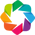

In [1]:
import warnings

warnings.filterwarnings("ignore")  # hide backend-mismatch style warnings in the docs

import io
from pathlib import Path

import holoviews as hv
import matplotlib.pyplot as plt
from IPython.display import Image, display

hv.extension("bokeh", "matplotlib")  # Bokeh = interactive (the default); matplotlib only for barbs / projection

# This notebook lives in docs/examples/interactive/guide/, so the bundled sample data at the repo-root
# examples/data/ is four levels up. The kernel's working directory is always the notebook's own folder
# (true for nbval, nbconvert and JupyterLab alike), so one clean relative path is all that is needed.
DATA = Path("../../../../examples/data")

from digitalearth.interactive import InteractiveMap
from pyramids.dataset import Dataset


def show(m, static=False):
    """Return the **live, interactive Bokeh map** - pan, zoom, hover, and the toolbar are all real.

    Run the notebook (Run All / Shift-Enter), or open it in a trusted viewer, to see the maps draw; a saved
    .ipynb only shows them once a kernel executes their JavaScript. A few layers have no Bokeh glyph
    (``projection``, ``streamlines``, wind ``barbs``) and are drawn by matplotlib; for those pass
    ``static=True`` (projected maps switch automatically) to embed a PNG instead.
    """
    if static or getattr(m, "_projection", None) is not None:
        fig = hv.render(m.render(), backend="matplotlib")
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
        plt.close(fig)
        return Image(data=buf.getvalue())
    return m.render()


In [2]:
import geopandas as gpd

adm1 = gpd.read_file(str(DATA / "germany_adm1.geojson")).to_crs(3857)
adm1_4326 = gpd.read_file(str(DATA / "germany_adm1.geojson"))
adm1_4326["area_km2"] = adm1_4326.to_crs(3035).area / 1e6
ncep = Dataset.read_file(str(DATA / "global" / "ncep_tavg_07.tif"))
print("states:", len(adm1))

states: 16


## `tiles` - a web-map basemap

`tiles` draws a slippy-map basemap under the data; `list_tile_providers()` lists the names.

In [3]:
InteractiveMap().list_tile_providers()[:8]

['CartoDark',
 'CartoEco',
 'CartoLight',
 'CartoMidnight',
 'EsriAntarcticImagery',
 'EsriArcticImagery',
 'EsriArcticOceanBase',
 'EsriArcticOceanReference']

In [4]:
m = InteractiveMap(crs=3857, title="German states on a Carto basemap")
m.tiles("CartoLight").polygons(adm1, line_color="firebrick", fill_alpha=0.05)
show(m)

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]   (shapeName,shapeISO,shapeType)

## `features` - Natural-Earth reference layers

`features` adds vector reference layers (land, rivers, lakes, borders) from Natural Earth.

In [5]:
m = InteractiveMap(crs=3857, title="states with land + rivers + lakes")
m.features(land=True, rivers=True, lakes=True).polygons(adm1, line_color="black", fill_alpha=0.0)
show(m)

:Overlay
   .Land.I     :Feature   [Longitude,Latitude]
   .Lakes.I    :Feature   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]   (shapeName,shapeISO,shapeType)
   .Rivers.I   :Feature   [Longitude,Latitude]

## `coastlines` - the Natural-Earth coastline

`coastlines` overlays the Natural-Earth coastline - Germany's North Sea and Baltic coasts here.

In [6]:
m = InteractiveMap(crs=3857, title="German states with coastlines")
m.coastlines().polygons(adm1, line_color="navy", fill_alpha=0.05)
show(m)

:Overlay
   .Polygons.I  :Polygons   [Longitude,Latitude]   (shapeName,shapeISO,shapeType)
   .Coastline.I :Feature   [Longitude,Latitude]

## `labels` and `text`

`labels` draws one label per feature from a column; `text` places a single caption at a coordinate.

In [7]:
name_col = "NAME_1" if "NAME_1" in adm1_4326.columns else adm1_4326.columns[0]
m = InteractiveMap(crs=4326, title="labelled states")
m.choropleth(adm1_4326, "area_km2", cmap="viridis").colorbar()
m.labels(adm1_4326.assign(geometry=adm1_4326.representative_point()), name_col, text_font_size="7pt")
m.text(10.4, 48.3, "Bavaria", text_font_size="11pt", text_color="white")
show(m)

:Overlay
   .Polygons.I :Polygons   [Longitude,Latitude]   (area_km2)
   .Labels.I   :Labels   [x,y]   (shapeName)
   .Text.I     :Text   [x,y]

## `projection` and `graticule`

`projection` reprojects the whole map onto a cartographic projection (`"Robinson"`, `"Mollweide"`, ...) and
`graticule` overlays lat/lon lines; these render via matplotlib, so `show` returns a static image.

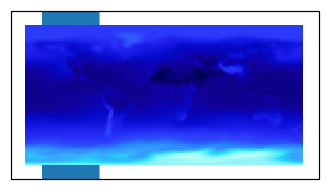

In [8]:
m = InteractiveMap(crs=4326, title="July temperature on a Robinson projection")
m.field(ncep, cmap="RdBu_r").projection("Robinson").graticule()
show(m, static=True)

## `theme` - restyle the whole figure

`theme` sets the Bokeh renderer theme for every layer; pass `None` to restore the default.

In [9]:
m = InteractiveMap(crs=4326, title="night_sky theme")
m.theme("night_sky").choropleth(adm1_4326, "area_km2", cmap="viridis").colorbar()
show(m)

:Polygons   [Longitude,Latitude]   (area_km2)